In [1]:
#First import the relevant packages
import pandas as pd

#import dataset
StudentsPerformance = pd.read_csv('StudentsPerformance.csv') #import the file. If the file is not in the same location as this script you need to write out the whole path
StudentsPerformance.head() #Check the first 5 entries



,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [2]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


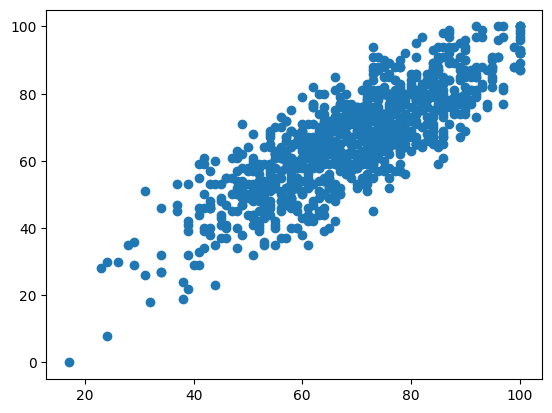

In [4]:
#Making Scatterplots

#first import the relevant package
import matplotlib.pyplot as plt

#Extract the relevant variables
reading_score = StudentsPerformance['reading_score']
math_score = StudentsPerformance['math_score']

#Create basic scatterplot between reading_score (x-axis) and math_score (y-axis)
plt.scatter(reading_score, math_score)



Text(0, 0.5, 'Math Score')

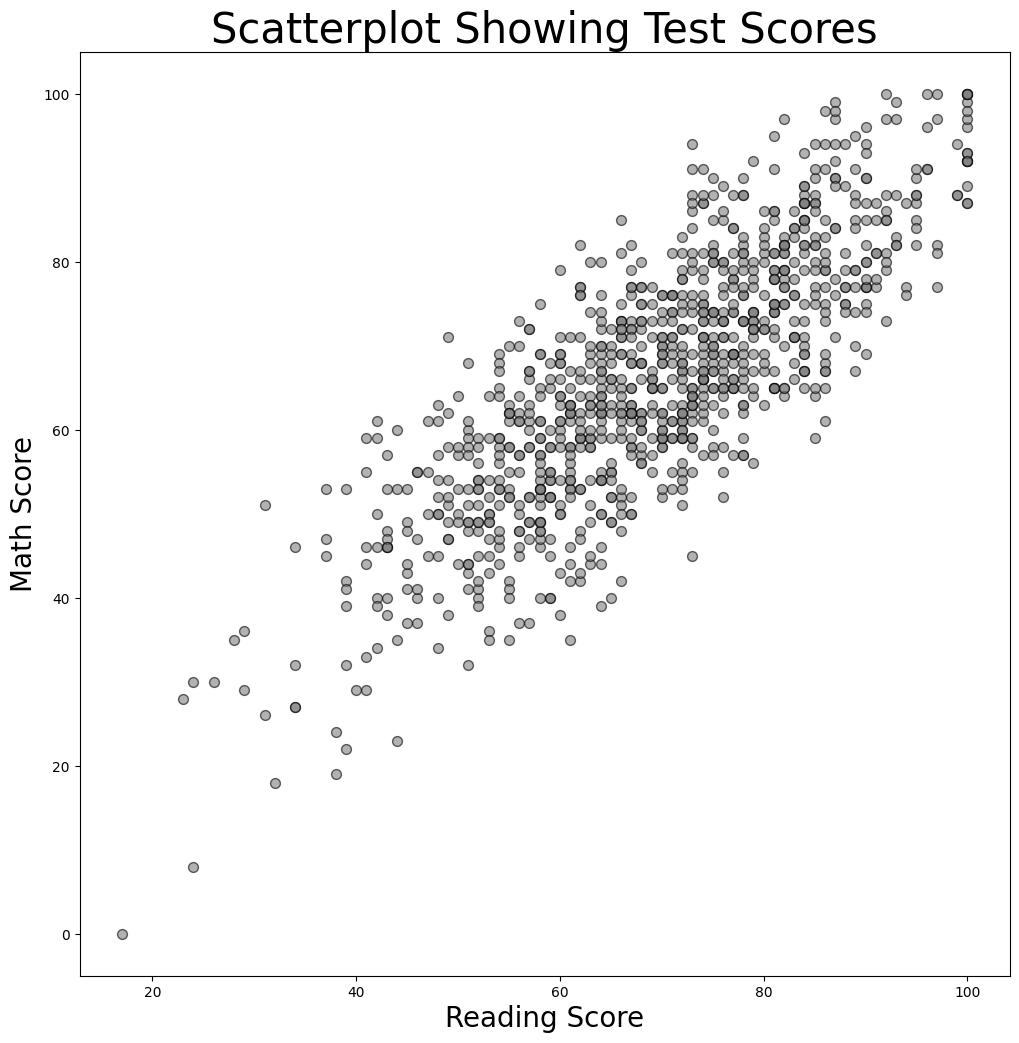

In [3]:
#Making the scatterplot look better
plt.figure(figsize=(12,12)) #Making the scatterplot bigger (this line always has to go first). Warning: it messes up the code above so you need to restart the kernel if you want to run the above code.

#Change how the dots look
plt.scatter(reading_score, math_score,
           s=50,alpha=0.6,color='grey', edgecolor='black') 
#s changes the size of the dots, alpha changes transparancy, color changes the dot's colors, edgecolor the color around the dots

#Add title and axis labels
plt.title('Scatterplot Showing Test Scores',fontsize=30)
plt.xlabel('Reading Score',fontsize=20)
plt.ylabel('Math Score',fontsize=20)



In [4]:
#correlations

#We will use the scipy package
import scipy.stats

#calculate the correlation (also known as Pearson's r)
scipy.stats.pearsonr(reading_score,math_score)

#the ouput shows two numbers: 
#the first shows the correlation coefficient (here: 0.817579663672054)
#the second shows the p-value (here: 1.787753109905834e-241)
    #note that 1.787753109905834e-241 means 1.787753109905834 * (1/10^241). So in other words, a very very very small number. 
    #in practical terms this means that it is very statistically significant because a smaller p-value means it's more significant



PearsonRResult(statistic=np.float64(0.8175796636720541), pvalue=np.float64(1.7877531099062542e-241))

               reading_score  writing_score  math_score
reading_score       1.000000       0.954598    0.817580
writing_score       0.954598       1.000000    0.802642
math_score          0.817580       0.802642    1.000000


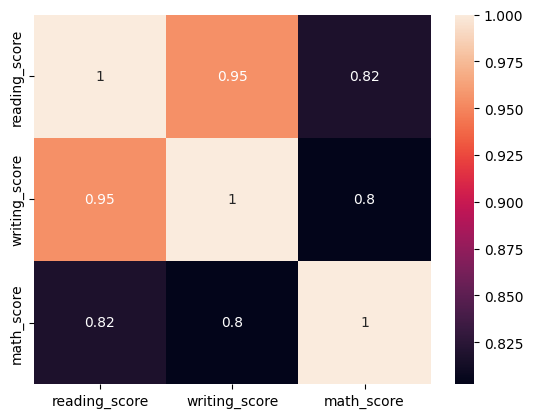

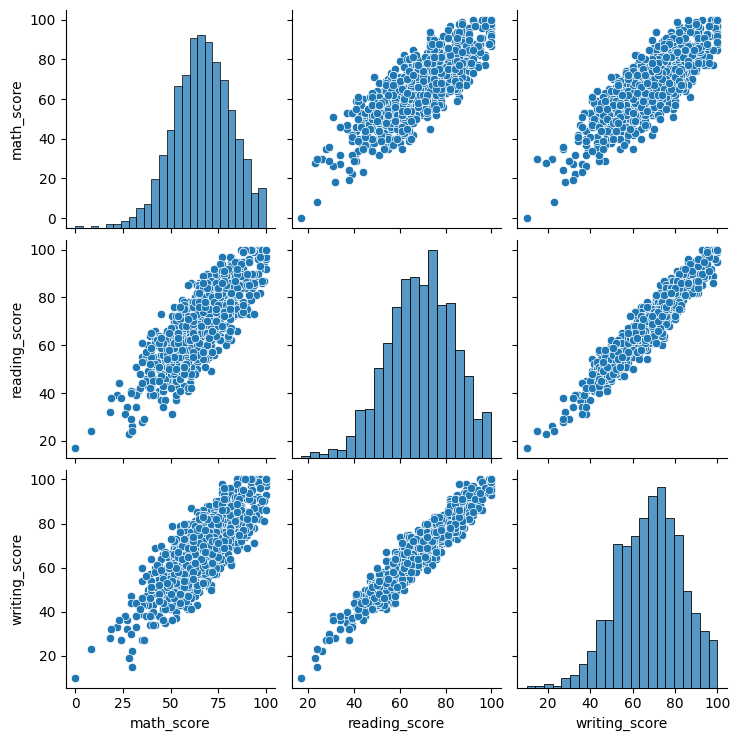

In [5]:
#correlation matrix (it will only include numerical values)
data = StudentsPerformance[['reading_score','writing_score','math_score']] #using [[ ]] allows you to select specific columns
matrix = data.corr()
print(matrix)

#heatmap (makes it easier to see the correlations, especially if there are many variables)
import seaborn as sn
sn.heatmap(matrix, annot=True) #the annot part shows the correlation coefficient numbers in the squares

#scatterplot matrix (the bar graphs show the distribution of the variables)
sn.pairplot(StudentsPerformance)

In [ ]:
#regression

#first import the excel file with pandas
import pandas as pd
house_prices = pd.read_excel('house_prices.xlsx')
house_prices.head()

,square_meters,num_rooms,price_euro
0,45,1,290000
1,60,2,430000
2,75,2,210000
3,100,3,770000
4,70,3,345000


In [12]:
import statsmodels.api as sm

y = house_prices['price_euro'] #define the dependent variable
X = house_prices['square_meters'] #define the independent variable
X = sm.add_constant(X) #add an intercept (DON'T FORGET!)

model1 = sm.OLS(y,X) #create the model by putting in the variables (has to be in this order!)
results = model1.fit() #produce results by fitting the model to the data
print(results.summary()) #print a summary of the model results

                            OLS Regression Results                            
Dep. Variable:             price_euro   R-squared:                       0.710
Model:                            OLS   Adj. R-squared:                  0.674
Method:                 Least Squares   F-statistic:                     19.60
Date:                Tue, 23 Jun 2026   Prob (F-statistic):            0.00220
Time:                        14:24:43   Log-Likelihood:                -130.42
No. Observations:                  10   AIC:                             264.8
Df Residuals:                       8   BIC:                             265.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          4.378e+04   1.19e+05      0.367

In [13]:
#Regression method 2
import statsmodels.formula.api as sm

model1 = sm.ols('price_euro ~ square_meters', data = house_prices).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:             price_euro   R-squared:                       0.710
Model:                            OLS   Adj. R-squared:                  0.674
Method:                 Least Squares   F-statistic:                     19.60
Date:                Tue, 23 Jun 2026   Prob (F-statistic):            0.00220
Time:                        14:32:29   Log-Likelihood:                -130.42
No. Observations:                  10   AIC:                             264.8
Df Residuals:                       8   BIC:                             265.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      4.378e+04   1.19e+05      0.367